
# Hierarchical Clustering - From Zero to Hero

**Hierarchical clustering** builds a **tree of clusters**. Instead of producing one flat answer,
it shows how the data groups together at *every* level of similarity - from 282 separate points,
to a few natural groups, all the way up to one big cluster.

That tree is called a **dendrogram** (from the Greek *dendron*, "tree").

### The family-tree analogy

Think of a family tree:

- at the bottom are the individual people (points),
- brothers and sisters join at a low height (very similar),
- cousins join a little higher,
- whole branches of the family join near the top.

Hierarchical clustering does exactly this with data points. The **height** at which two
branches join tells you **how different** those groups are.

### What you will learn

1. What hierarchical clustering is and how it differs from K-Means and DBSCAN.
2. **Agglomerative** (bottom-up) clustering, step by step.
3. The four **linkage** methods: single, complete, average and Ward.
4. How to read and **cut a dendrogram**.
5. A real **from-scratch implementation** and how to check it against SciPy.
6. An **interactive** playground: change the linkage, the number of clusters and the metric.
7. How to choose the number of clusters with the dendrogram and the silhouette score.
8. How hierarchical clustering compares with K-Means and DBSCAN.

> **Note:** The dataset is synthetic (fake) and ships as `hierarchical_points.csv`. It has
> **282 points** with coordinates `x` and `y`, plus a `true_group` column used only to *generate*
> the data. The clustering code never reads `true_group`; we compare against it at the end.



## 1. What is hierarchical clustering?

### The one-sentence idea

> Start with every point as its own cluster, repeatedly merge the two closest clusters, and record
> every merge as a branch in a tree.

### Two directions

| Direction | How it works | Common? |
|---|---|---|
| **Agglomerative** (bottom-up) | Start with `n` singleton clusters, merge the closest pair again and again | Yes - this is what "hierarchical clustering" usually means |
| **Divisive** (top-down) | Start with one big cluster, repeatedly split it | Less common (slower) |

This notebook focuses on **agglomerative** clustering.

### Why is it useful?

- You do **not** need to choose the number of clusters in advance. You build the whole tree once,
  then decide where to cut it.
- The dendrogram is a **visual explanation** of the grouping - great for reports.
- It is **deterministic**: no random initialisation, so you get the same answer every run.
- It naturally gives you clusters at **multiple granularities**.

### The cost

- It needs a **pairwise distance matrix**: `O(n^2)` memory.
- Naive agglomerative clustering is `O(n^3)` time (optimised versions are `O(n^2 log n)`).
- So it is great for hundreds or a few thousand points, not for millions.



## 2. The agglomerative algorithm, step by step

```
1. Compute the distance between every pair of points.

2. Make each point its own cluster:  n points -> n clusters.

3. Repeat until only one cluster is left:
     a. find the two clusters that are closest to each other
     b. merge them into one new cluster
     c. record: which two clusters merged, at what height, and the new size
     d. update the distances from the new cluster to all remaining clusters

4. The recorded merges form the dendrogram.
   Cut it at a chosen height to get the final clusters.
```

The interesting part is **step 3a**: what does "closest" mean when a cluster contains many points?
That is the **linkage** question, and it is the subject of the next section.

### A tiny worked example

Points `A, B, C` with distances `AB = 1`, `AC = 4`, `BC = 5`:

1. Each point is a cluster.
2. The closest pair is `A` and `B` (distance 1) -> merge into `AB` at height 1.
3. Now there are two clusters: `AB` and `C`. Merge them at the linkage distance.
4. The tree has a branch joining `A` and `B` low down, and `C` joins higher up.



## 3. Linkage - the heart of hierarchical clustering

When cluster `A` has several points and cluster `B` has several points, there are many pairwise
distances between them. **Linkage** decides which one (or which combination) to use.

| Linkage | Distance between clusters A and B | Personality |
|---|---|---|
| **Single** | the **minimum** pairwise distance | Follows chains and curved shapes; can "bridge" separate clusters |
| **Complete** | the **maximum** pairwise distance | Compact, tight clusters; sensitive to outliers |
| **Average** | the **mean** of all pairwise distances | A balanced compromise; very popular |
| **Ward** | the merge that increases **within-cluster variance** the least | Round, similar-sized clusters; needs Euclidean distance |

### How to remember them

- **Single** = "the two clusters are as close as their closest pair." Very optimistic.
  It can walk along a thin bridge of points and merge things that should stay apart - this is
  called **chaining**.
- **Complete** = "the two clusters are as far apart as their farthest pair." Very pessimistic.
  Every point must be reasonably close before the clusters merge.
- **Average** = "on average, how far apart are they?" The diplomat.
- **Ward** = "which merge creates the least messy, most compact group?" It is the default in many
  tools, including scikit-learn.

The plot below makes single, complete and average concrete for two toy clusters.



## 4. Setup - the tools we need

- **NumPy** for distances and the from-scratch algorithm.
- **Pandas** to load the CSV.
- **Matplotlib** for every chart.
- **SciPy** for `linkage`, `dendrogram`, `fcluster` and `cophenet`.
- **scikit-learn** for `AgglomerativeClustering`, `KMeans`, `DBSCAN` and metrics.
- **ipywidgets** for the sliders and dropdowns.


In [1]:

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

import ipywidgets as widgets
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, fixed
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 11

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
import sklearn, scipy
print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__)


numpy        2.5.4
pandas       3.1.1
scikit-learn 1.9.1
scipy        1.18.1



## 5. Load the fake dataset

`hierarchical_points.csv` has 282 rows:

| Column | Meaning |
|---|---|
| `id` | A unique number for each point |
| `x` | Horizontal coordinate |
| `y` | Vertical coordinate |
| `true_group` | The group used to *generate* the point (ignored by the algorithm) |

The data was designed with:

- **two round blobs** - easy for every linkage,
- **one curved arc** - non-spherical,
- **one thin elongated chain** - single linkage loves it, complete/Ward tend to split it,
- **12 random noise points** - hierarchical clustering has no concept of noise, so they will be
  forced into clusters. That is itself an important lesson.


In [2]:

df = pd.read_csv("hierarchical_points.csv")
df.head(10)


,id,x,y,true_group
0,1,2.000,2.119,blob_A
1,2,1.890,1.644,blob_A
2,3,1.818,1.603,blob_A
3,4,2.024,2.536,blob_A
4,5,1.803,1.752,blob_A
5,6,2.196,2.143,blob_A
6,7,2.042,1.628,blob_A
7,8,1.988,2.278,blob_A
8,9,1.462,1.817,blob_A
9,10,1.240,1.484,blob_A


In [3]:

print("shape:", df.shape)
print("\nmissing values per column:")
print(df.isna().sum())
print("\nsummary statistics:")
df.describe().round(2)


shape: (282, 4)

missing values per column:
id            0
x             0
y             0
true_group    0
dtype: int64

summary statistics:


,id,x,y
count,282.00,282.00,282.00
mean,141.50,5.35,5.19
std,81.55,2.58,2.62
min,1.00,-0.33,0.99
25%,71.25,2.98,2.13
50%,141.50,5.76,5.71
75%,211.75,7.92,7.72
max,282.00,9.33,10.08



### The raw points (what the algorithm sees)

Just `x` and `y` - no colours, no groups.


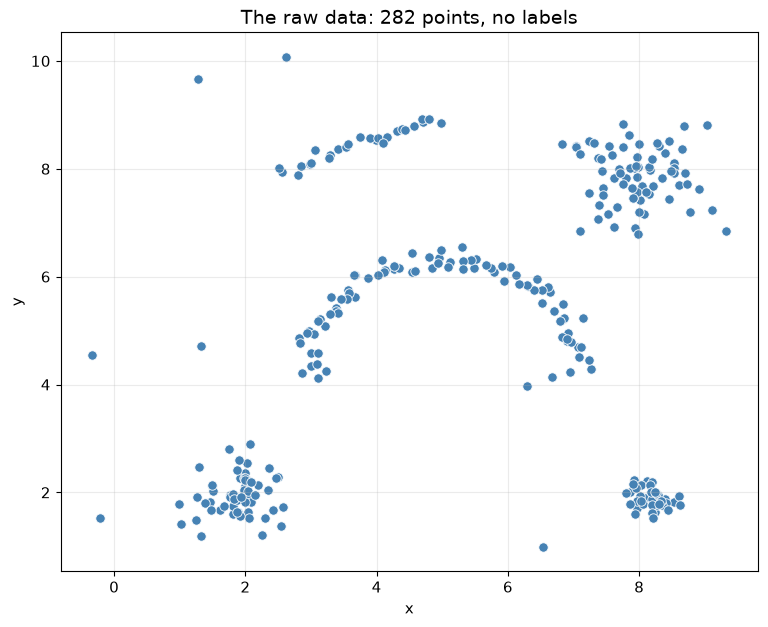

In [4]:

X = df[["x", "y"]].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(X[:, 0], X[:, 1], s=46, c="steelblue", edgecolors="white", linewidths=0.6)
ax.set_title("The raw data: 282 points, no labels", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()



### The hidden truth (for our eyes only)

Colouring by `true_group` shows how the data was generated. The algorithm never sees this.


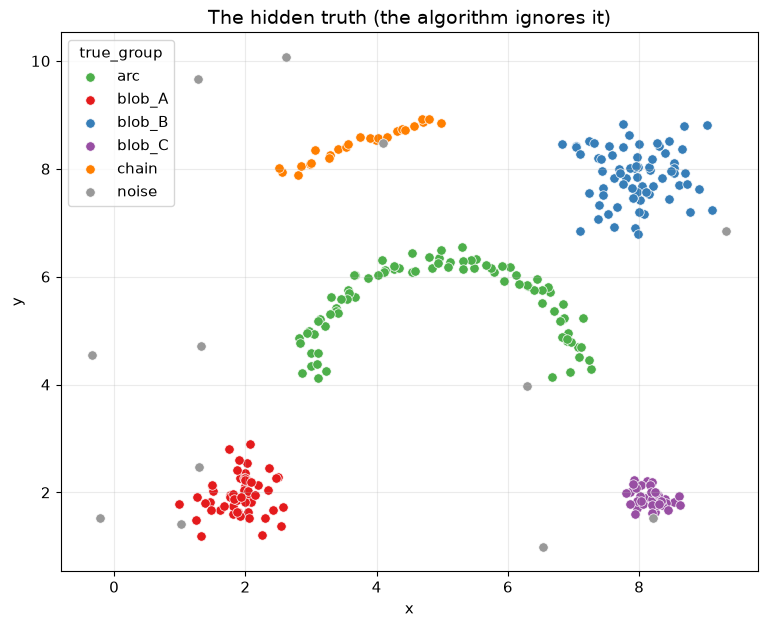

In [5]:

TRUE_COLORS = {
    "blob_A": "#e41a1c",
    "blob_B": "#377eb8",
    "arc": "#4daf4a",
    "blob_C": "#984ea3",
    "chain": "#ff7f00",
    "noise": "#999999",
}

fig, ax = plt.subplots(figsize=(9, 7))
for group, sub in df.groupby("true_group"):
    ax.scatter(sub["x"], sub["y"], s=46, color=TRUE_COLORS[group],
               label=group, edgecolors="white", linewidths=0.5)
ax.set_title("The hidden truth (the algorithm ignores it)", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(title="true_group")
plt.show()



## 6. The distance matrix

Hierarchical clustering works from a **pairwise distance matrix**: `D[i, j]` is the distance
between point `i` and point `j`.

If the data has clear groups, the matrix - when its rows and columns are sorted by group - shows
**bright square blocks**: points inside a group are close (dark), points in different groups are
far (bright). That block structure is exactly what the dendrogram will discover.


In [6]:

def pairwise_distances(X):
    """Straight-line (Euclidean) distance between every pair of points."""
    diff = X[:, None, :] - X[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=2))


D = pairwise_distances(X)
print("distance matrix shape:", D.shape)
print("smallest non-zero distance:", round(D[D > 0].min(), 3))
print("largest distance:          ", round(D.max(), 3))


distance matrix shape: (282, 282)
smallest non-zero distance: 0.004
largest distance:           11.78


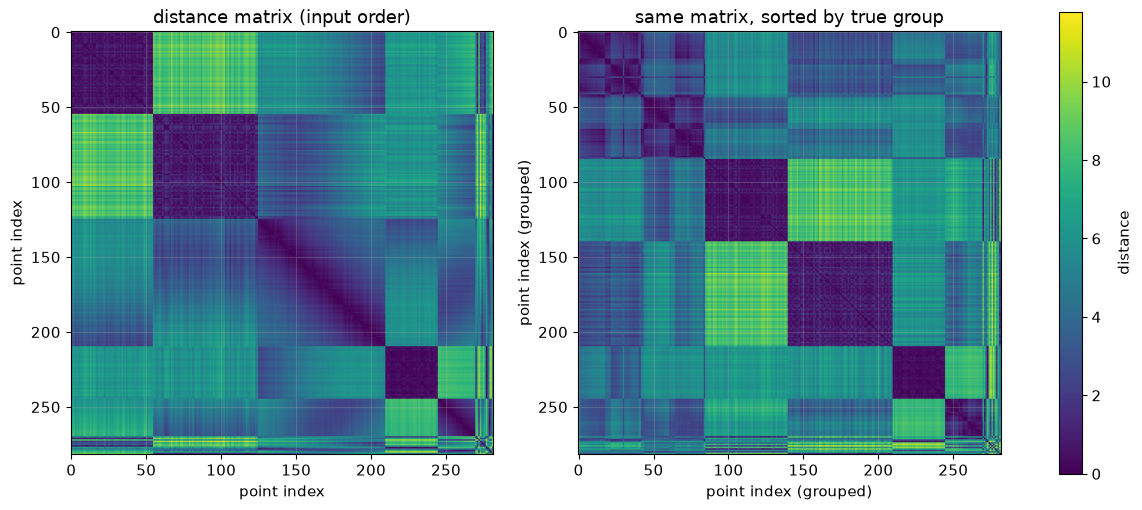

In [7]:

order = np.argsort(df["true_group"].values)   # only for the right-hand picture

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
im0 = axes[0].imshow(D, cmap="viridis")
axes[0].set_title("distance matrix (input order)")
axes[0].set_xlabel("point index")
axes[0].set_ylabel("point index")

im1 = axes[1].imshow(D[np.ix_(order, order)], cmap="viridis")
axes[1].set_title("same matrix, sorted by true group")
axes[1].set_xlabel("point index (grouped)")
axes[1].set_ylabel("point index (grouped)")

fig.colorbar(im1, ax=axes.ravel().tolist(), label="distance")
plt.show()



## 7. What single, complete and average look like

Two toy clusters, `A` and `B`. Every grey line is one pairwise distance between a point of `A`
and a point of `B`.

- **Single linkage** uses the **shortest** grey line (red).
- **Complete linkage** uses the **longest** grey line (blue).
- **Average linkage** uses the **mean** of all grey lines (written in the corner).


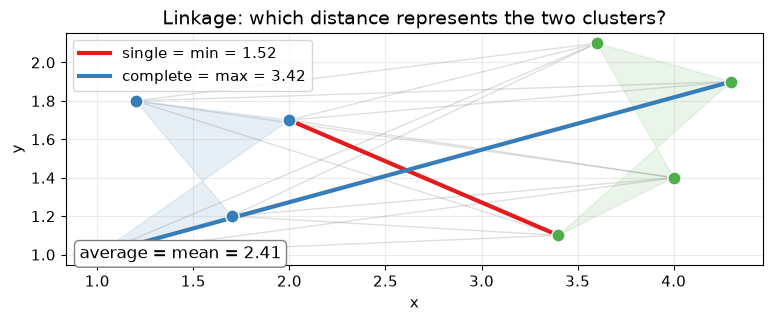

In [8]:

A = np.array([[1.0, 1.0], [1.7, 1.2], [1.2, 1.8], [2.0, 1.7]])
B = np.array([[3.4, 1.1], [4.0, 1.4], [3.6, 2.1], [4.3, 1.9]])

dist = np.linalg.norm(A[:, None, :] - B[None, :, :], axis=2)
single = dist.min()
complete = dist.max()
average = dist.mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.add_patch(Polygon(A, closed=True, alpha=0.12, color="#377eb8"))
ax.add_patch(Polygon(B, closed=True, alpha=0.12, color="#4daf4a"))
ax.scatter(A[:, 0], A[:, 1], s=90, c="#377eb8", edgecolors="white", zorder=3)
ax.scatter(B[:, 0], B[:, 1], s=90, c="#4daf4a", edgecolors="white", zorder=3)

for a in A:
    for b in B:
        ax.plot([a[0], b[0]], [a[1], b[1]], color="grey", alpha=0.25, lw=1)

i, j = np.unravel_index(np.argmin(dist), dist.shape)
ax.plot([A[i, 0], B[j, 0]], [A[i, 1], B[j, 1]], color="#e41a1c", lw=3,
        label=f"single = min = {single:.2f}")
i, j = np.unravel_index(np.argmax(dist), dist.shape)
ax.plot([A[i, 0], B[j, 0]], [A[i, 1], B[j, 1]], color="#377eb8", lw=3,
        label=f"complete = max = {complete:.2f}")

ax.text(0.02, 0.03, f"average = mean = {average:.2f}", transform=ax.transAxes,
        fontsize=12, bbox=dict(boxstyle="round", fc="white", ec="grey"))
ax.set_title("Linkage: which distance represents the two clusters?", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.legend()
plt.show()



## 8. Hierarchical clustering from scratch

We will implement the algorithm ourselves. To update distances efficiently we use the
**Lance-Williams** formula:

$$d(A \cup B,\; C) = \alpha_A\, d(A,C) + \alpha_B\, d(B,C) + \beta\, d(A,B)
+ \gamma\, \lvert d(A,C) - d(B,C) \rvert$$

The coefficients depend on the linkage:

| Linkage | alpha_A | alpha_B | beta | gamma |
|---|---|---|---|---|
| Single | 1/2 | 1/2 | 0 | -1/2 |
| Complete | 1/2 | 1/2 | 0 | +1/2 |
| Average | n_A / (n_A+n_B) | n_B / (n_A+n_B) | 0 | 0 |
| Ward | (n_A+n_C) / (n_A+n_B+n_C) | (n_B+n_C) / (n_A+n_B+n_C) | -n_C / (n_A+n_B+n_C) | 0 |

For **Ward**, the formula works on **squared** distances, so we run it on `D ** 2` and take the
square root of each merge height at the end.

The function below returns a list of merges:

```
(which_cluster_1, which_cluster_2, merge_height, new_size)
```

Cluster ids `0..n-1` are the original points; merged clusters get new ids `n, n+1, ...`.


In [9]:

def agglomerative_clustering(D, method="average"):
    """Lance-Williams agglomerative clustering.

    D       : (n, n) distance matrix (use squared distances for Ward)
    method  : 'single', 'complete', 'average' or 'ward'
    returns : list of (cluster_a, cluster_b, height, new_size)
    """
    n = len(D)
    M = np.full((2 * n, 2 * n), np.inf)     # distance between any two cluster ids
    M[:n, :n] = D
    active = list(range(n))
    sizes = {i: 1 for i in range(n)}
    merges = []
    next_id = n

    for _ in range(n - 1):
        # ---- find the closest pair of active clusters ----
        best = np.inf
        a = b = None
        for i in range(len(active)):
            for j in range(i + 1, len(active)):
                u, v = active[i], active[j]
                if M[u, v] < best:
                    best, a, b = M[u, v], u, v

        na, nb = sizes[a], sizes[b]
        new = next_id
        next_id += 1
        sizes[new] = na + nb

        # ---- update the distance from the new cluster to every other cluster ----
        for other in active:
            if other in (a, b):
                continue
            nc = sizes[other]
            dac, dbc = M[a, other], M[b, other]
            if method == "single":
                dnew = min(dac, dbc)
            elif method == "complete":
                dnew = max(dac, dbc)
            elif method == "average":
                dnew = (na * dac + nb * dbc) / (na + nb)
            elif method == "ward":
                dnew = ((na + nc) * dac + (nb + nc) * dbc - nc * best) / (na + nb + nc)
            else:
                raise ValueError(f"unknown method: {method}")
            M[new, other] = M[other, new] = dnew

        merges.append((a, b, best, na + nb))
        active.remove(a)
        active.remove(b)
        active.append(new)

    return merges


In [10]:

def fit_scratch(X, method="average"):
    """Run the from-scratch algorithm and return scipy-compatible merge heights."""
    D = pairwise_distances(X)
    if method == "ward":
        merges = agglomerative_clustering(D ** 2, "ward")
        return [(a, b, float(np.sqrt(h)), s) for a, b, h, s in merges]
    return agglomerative_clustering(D, method)



### Check the from-scratch code against SciPy

SciPy's `linkage` is the reference implementation. For each linkage method we compare the
**merge heights** and the **cluster sizes** of every merge. The largest difference should be
essentially zero (floating-point noise).


In [11]:

for method in ["single", "complete", "average", "ward"]:
    mine = fit_scratch(X, method)
    ref = linkage(X, method=method)

    my_heights = np.array([m[2] for m in mine])
    my_sizes = np.array([m[3] for m in mine])
    ref_heights = ref[:, 2]
    ref_sizes = ref[:, 3].astype(int)

    print(f"{method:9s}  heights match: {str(np.allclose(my_heights, ref_heights)):<5}  "
          f"sizes match: {str(np.array_equal(my_sizes, ref_sizes)):<5}  "
          f"max height diff: {np.max(np.abs(my_heights - ref_heights)):.2e}")


single     heights match: True   sizes match: True   max height diff: 0.00e+00


complete   heights match: True   sizes match: True   max height diff: 0.00e+00


average    heights match: True   sizes match: True   max height diff: 8.88e-16


ward       heights match: True   sizes match: True   max height diff: 1.42e-14



## 9. Watch the tree being built, merge by merge

The slider moves through the merges. At merge `0`, every point is its own cluster. At the end,
everything is one cluster.

- **Left:** the clusters at that moment.
- **Right:** the merge heights. The red dot shows where we are. Notice how the heights jump:
  small jumps are similar points joining, big jumps are very different groups joining.

The default is 5 clusters (277 merges). Try moving it earlier to see the small clusters form,
then later to watch them merge into big groups.


In [12]:

def labels_after_merges(n, merges, n_merges):
    """Apply the first n_merges merges and return one label per original point."""
    parent = list(range(2 * n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    for a, b, h, size in merges[:n_merges]:
        union(a, b)

    labels = np.array([find(i) for i in range(n)])
    _, labels = np.unique(labels, return_inverse=True)
    return labels


merges_avg = fit_scratch(X, "average")
heights_avg = np.array([m[2] for m in merges_avg])
print("merges recorded:", len(merges_avg))


merges recorded: 281


In [13]:

def show_merges(n_merge):
    labels = labels_after_merges(len(X), merges_avg, n_merge)
    k = len(np.unique(labels))
    palette = plt.cm.tab20(np.linspace(0, 1, max(k, 1)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6),
                                   gridspec_kw={"width_ratios": [1.25, 1]})

    for c in range(k):
        m = labels == c
        ax1.scatter(X[m, 0], X[m, 1], s=42, c=[palette[c % 20]],
                    edgecolors="white", linewidths=0.35)
    ax1.set_title(f"after {n_merge} merges  ->  {k} clusters", fontsize=13)
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")

    ax2.plot(np.arange(1, len(heights_avg) + 1), heights_avg, color="#377eb8")
    if n_merge > 0:
        ax2.axvline(n_merge, color="#e41a1c", ls="--", lw=1.5)
        ax2.scatter([n_merge], [heights_avg[n_merge - 1]], color="#e41a1c", s=60, zorder=5)
    ax2.set_xlabel("merge number")
    ax2.set_ylabel("merge height (distance)")
    ax2.set_title("climbing the tree", fontsize=13)
    plt.tight_layout()
    plt.show()


interact(show_merges,
         n_merge=IntSlider(min=0, max=len(merges_avg), step=1,
                           value=len(merges_avg) - 4, description="merges"))


interactive(children=(IntSlider(value=277, description='merges', max=281), Output()), _dom_classes=('widget-in…

<function __main__.show_merges(n_merge)>


## 10. The dendrogram

A **dendrogram** is the picture of all the merges:

- each **leaf** at the bottom is a point (or, in a truncated view, a group of points),
- two branches join at the **height** where their clusters were merged,
- a **horizontal cut** through the tree gives the final clusters: everything below the cut
  in the same branch belongs to the same cluster.

The tree below uses **average linkage** and shows the last 35 merges, so the important structure
is readable. The number in brackets is how many original points are inside that leaf.


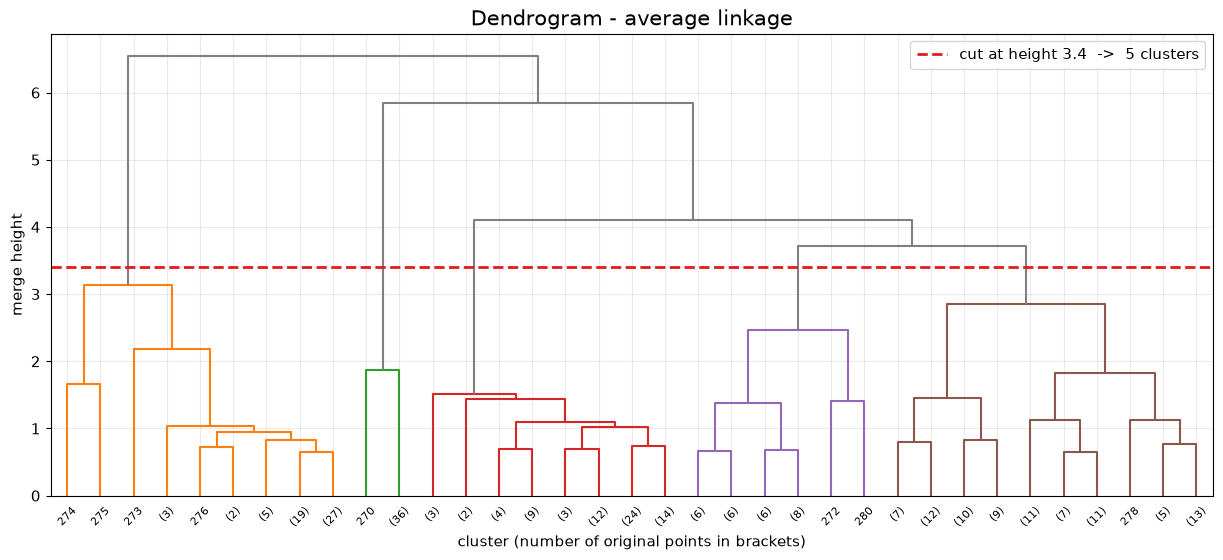

In [14]:

Z_avg = linkage(X, method="average")

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z_avg, ax=ax, truncate_mode="lastp", p=35, show_leaf_counts=True,
           color_threshold=3.4, above_threshold_color="grey")
ax.axhline(3.4, color="#e41a1c", ls="--", lw=2, label="cut at height 3.4  ->  5 clusters")
ax.set_title("Dendrogram - average linkage", fontsize=15)
ax.set_xlabel("cluster (number of original points in brackets)")
ax.set_ylabel("merge height")
ax.legend()
plt.show()



### Read it like a map

- The **lowest** joins (near the bottom) are the most similar points.
- Moving **up**, groups merge into bigger groups.
- A **long vertical gap** before a join means those two groups were quite different - that is a
  natural place to cut.
- Cutting at height `3.4` gives **5 clusters**, which matches the 5 groups used to generate the
  data (the 12 noise points get absorbed into nearby clusters).



## 11. Cut the dendrogram yourself

Move the slider to change the cut height. The title tells you how many clusters you get.

- Cut **low** -> many small clusters, each very tight.
- Cut **high** -> few big clusters.
- The "right" cut is usually just **before a big jump** in height.


In [15]:

def cut_dendrogram(height):
    labels = fcluster(Z_avg, t=height, criterion="distance")
    k = len(np.unique(labels))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6),
                                   gridspec_kw={"width_ratios": [1.45, 1]})

    dendrogram(Z_avg, ax=ax1, truncate_mode="lastp", p=35, show_leaf_counts=True,
               color_threshold=height, above_threshold_color="grey")
    ax1.axhline(height, color="#e41a1c", ls="--", lw=2, label=f"cut -> {k} clusters")
    ax1.set_title("dendrogram cut", fontsize=13)
    ax1.set_ylabel("merge height")
    ax1.legend()

    palette = plt.cm.tab10(np.linspace(0, 1, max(k, 1)))
    for c in range(k):
        m = labels == c
        ax2.scatter(X[m, 0], X[m, 1], s=45, c=[palette[c % 10]],
                    edgecolors="white", linewidths=0.5)
    ax2.set_title(f"result: {k} clusters", fontsize=13)
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    plt.tight_layout()
    plt.show()


interact(cut_dendrogram,
         height=FloatSlider(min=0.0, max=float(Z_avg[:, 2].max()) * 1.02,
                            step=0.05, value=3.4, description="cut height"))


interactive(children=(FloatSlider(value=3.4, description='cut height', max=6.6809258640583575, step=0.05), Out…

<function __main__.cut_dendrogram(height)>


## 12. The same thing with scikit-learn

`AgglomerativeClustering` does the whole job in one line. We ask for **5 clusters** with
**average linkage**, then score the result against the hidden truth.

- **Silhouette** measures how tight and well-separated the clusters are (higher is better).
- **Adjusted Rand Index (ARI)** measures agreement with `true_group` (1.0 = perfect).


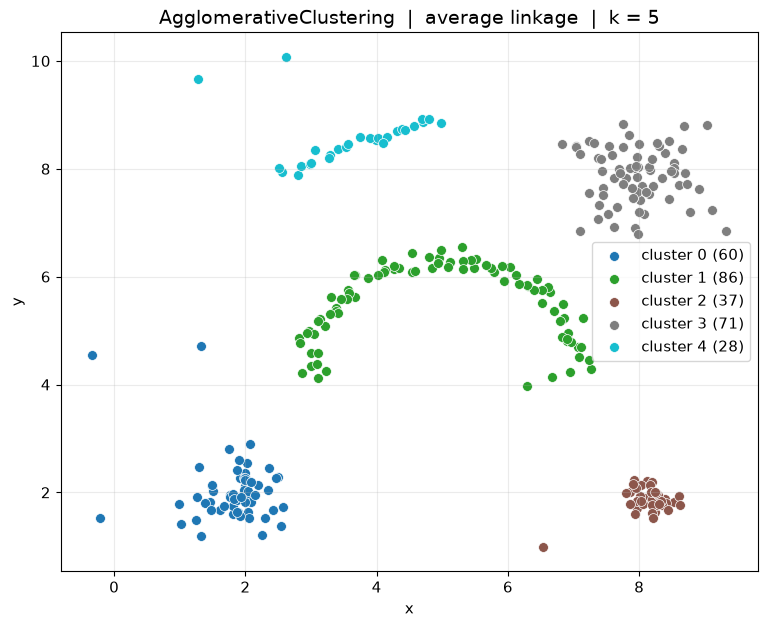

silhouette score: 0.645
ARI vs hidden truth: 0.954


In [16]:

agg = AgglomerativeClustering(n_clusters=5, linkage="average")
labels_agg = agg.fit_predict(X)

plot_labels = labels_agg
k = len(np.unique(plot_labels))
palette = plt.cm.tab10(np.linspace(0, 1, k))

fig, ax = plt.subplots(figsize=(9, 7))
for c in range(k):
    m = plot_labels == c
    ax.scatter(X[m, 0], X[m, 1], s=50, c=[palette[c]], label=f"cluster {c} ({m.sum()})",
               edgecolors="white", linewidths=0.5)
ax.set_title("AgglomerativeClustering  |  average linkage  |  k = 5", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.show()

print("silhouette score:", round(silhouette_score(X, labels_agg), 3))
print("ARI vs hidden truth:", round(adjusted_rand_score(df["true_group"], labels_agg), 3))



## 13. The four linkages, side by side

Same data, same number of clusters (`k = 5`), four different definitions of "closest".

Watch for:

- **Single** - the thin chain and the arc can pull distant groups together (**chaining**).
- **Complete** - tight, compact clusters; may split the elongated chain.
- **Average** - the balanced result.
- **Ward** - compact, round-ish clusters; may split the arc.

The ARI in each title is the agreement with the hidden truth (ignoring the noise label problem).


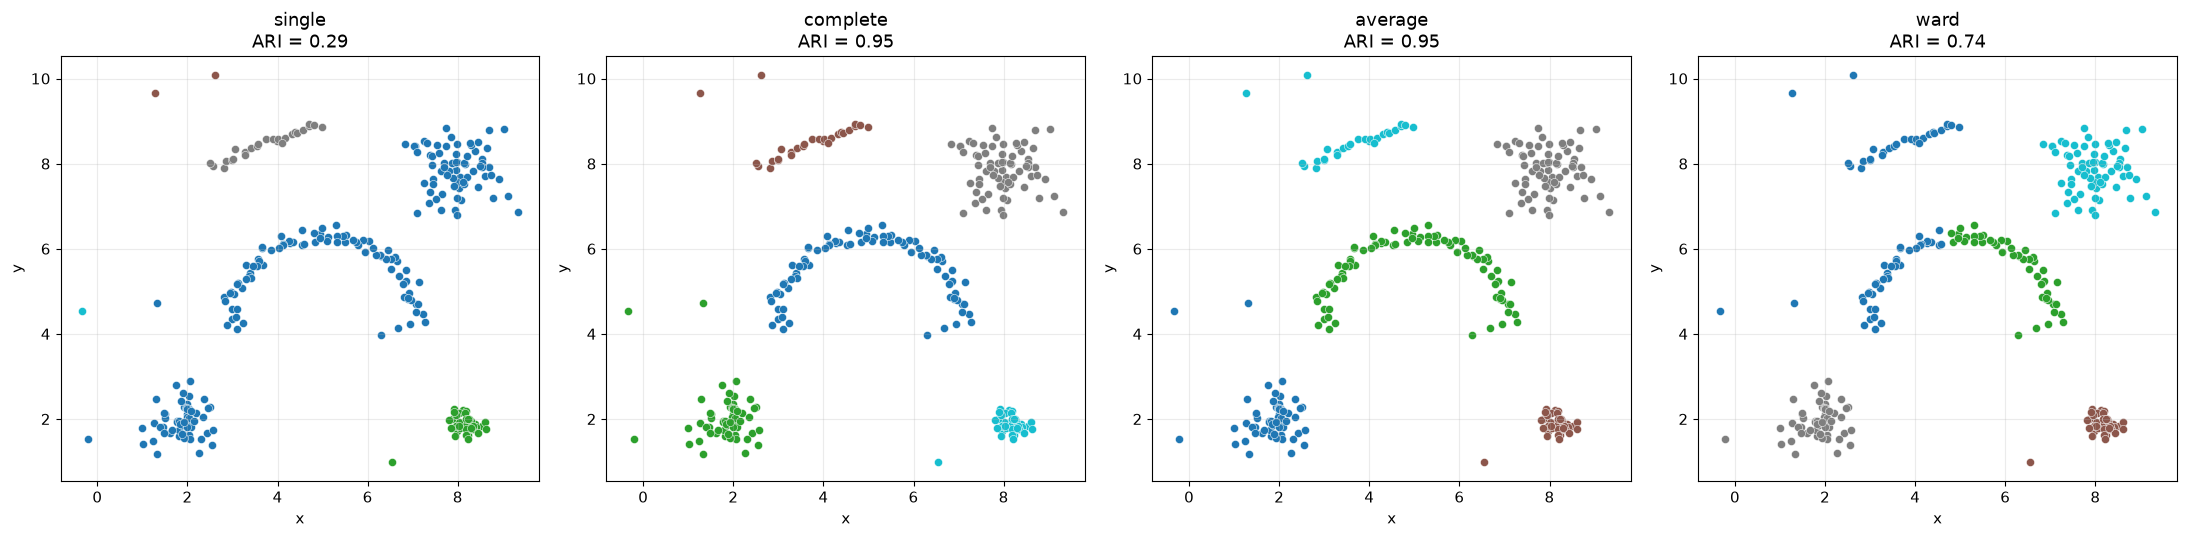

In [17]:

METHODS = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, method in zip(axes, METHODS):
    labels = AgglomerativeClustering(n_clusters=5, linkage=method).fit_predict(X)
    ari = adjusted_rand_score(df["true_group"], labels)
    palette = plt.cm.tab10(np.linspace(0, 1, 5))
    for c in range(5):
        m = labels == c
        ax.scatter(X[m, 0], X[m, 1], s=34, c=[palette[c]],
                   edgecolors="white", linewidths=0.35)
    ax.set_title(f"{method}\nARI = {ari:.2f}", fontsize=13)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()



### Which one wins here?

**Average** and **complete** do best on this dataset (ARI about 0.95), because the clusters are
compact and the thin chain is a real group. **Single** suffers from chaining. **Ward** prefers
round blobs, so the curved arc and the thin chain are harder for it.

There is no universal winner - the right linkage depends on the **shape** of your clusters.



## 14. The classic failure case: two moons

This is the same experiment as in the DBSCAN notebook, but now with hierarchical clustering.

- **Single linkage** can follow the curved moons, because it only needs the *nearest* pair to be
  close. It often recovers both moons.
- **Complete**, **average** and **Ward** prefer compact clusters, so they cut across the moons.

This is the hierarchical version of the lesson: **the linkage is a prior about cluster shape**.


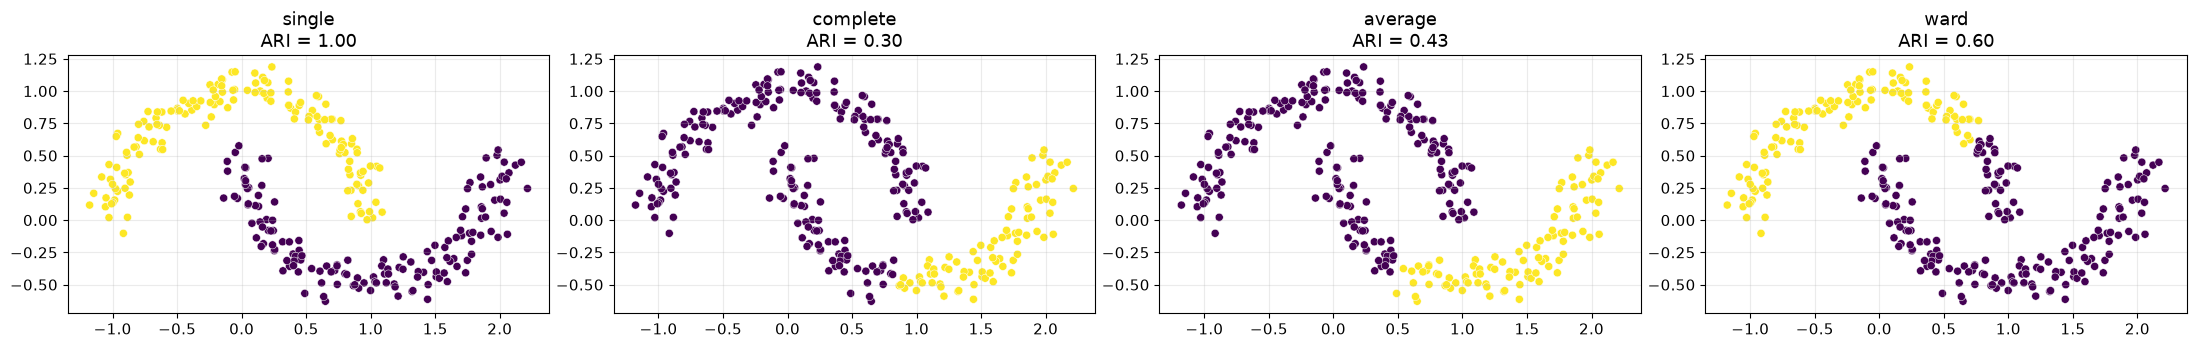

In [18]:

X_moons, y_moons = make_moons(n_samples=300, noise=0.08, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, method in zip(axes, METHODS):
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_moons)
    ari = adjusted_rand_score(y_moons, labels)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap="viridis",
               s=34, edgecolors="white", linewidths=0.35)
    ax.set_title(f"{method}\nARI = {ari:.2f}", fontsize=13)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()



## 15. Choosing the number of clusters

Hierarchical clustering gives you the whole tree, so you still have to decide **where to cut**.
Two useful tools:

### 1. The dendrogram gap

Look for the largest vertical jump in the last few merges. Cutting just below that jump usually
gives a sensible number of clusters.

### 2. The silhouette score

For each candidate `k`, compute the average silhouette. Higher is better. But be careful:
silhouette prefers compact, well-separated clusters, so it can disagree with the "true" shape.

The plot below shows silhouette versus `k` for all four linkages. The dotted line is the true
number of generated groups (`k = 5`).


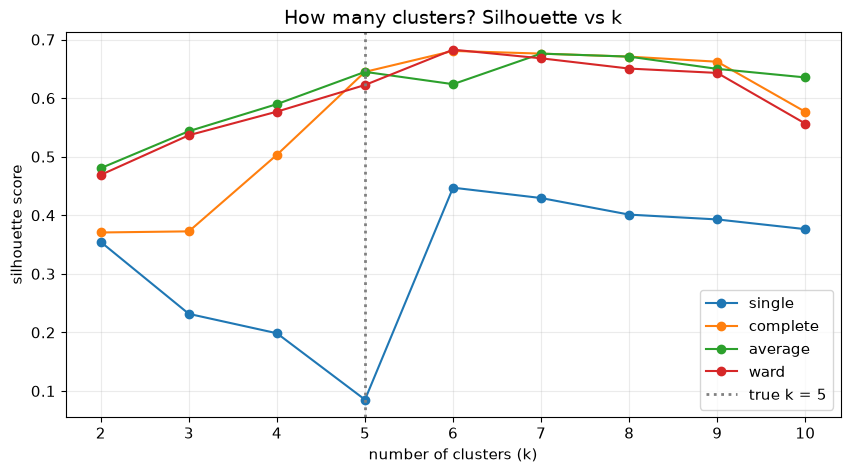

In [19]:

ks = list(range(2, 11))
fig, ax = plt.subplots(figsize=(10, 5))

for method in METHODS:
    scores = [silhouette_score(X, AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X))
              for k in ks]
    ax.plot(ks, scores, marker="o", label=method)

ax.axvline(5, color="grey", ls=":", lw=2, label="true k = 5")
ax.set_xlabel("number of clusters (k)")
ax.set_ylabel("silhouette score")
ax.set_title("How many clusters? Silhouette vs k", fontsize=14)
ax.legend()
plt.show()



### Reading the result

- **Average** peaks near `k = 5`, which is reassuring.
- **Complete** and **Ward** keep improving a little up to `k = 6`, because they split the arc or
  the chain into extra pieces.
- **Single** is erratic - chaining makes the silhouette unreliable.

**Practical advice:** use the dendrogram as the main guide, the silhouette as a second opinion,
and your knowledge of the problem as the tie-breaker. There is no automatic "correct k".



## 16. Interactive playground

Change the **linkage**, the **number of clusters** and the **distance metric**, and watch the
result update.

Things to try:

- `single` + `cosine` - a very different notion of similarity.
- `complete` + `manhattan` - blocky, city-block distances.
- `ward` only supports Euclidean; the notebook will switch back automatically if you pick another
  metric.

The silhouette score is printed below each plot.


In [20]:

def playground(linkage_method, n_clusters, metric):
    if linkage_method == "ward" and metric != "euclidean":
        print("Ward linkage only supports the euclidean metric - switching back to euclidean.")
        metric = "euclidean"

    labels = AgglomerativeClustering(n_clusters=n_clusters,
                                     linkage=linkage_method,
                                     metric=metric).fit_predict(X)

    k = len(np.unique(labels))
    palette = plt.cm.tab10(np.linspace(0, 1, k))
    fig, ax = plt.subplots(figsize=(9, 7))
    for c in range(k):
        m = labels == c
        ax.scatter(X[m, 0], X[m, 1], s=48, c=[palette[c]], label=f"cluster {c} ({m.sum()})",
                   edgecolors="white", linewidths=0.5)
    ax.set_title(f"{linkage_method} linkage  |  k = {n_clusters}  |  {metric}", fontsize=14)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    plt.show()
    print("silhouette:", round(silhouette_score(X, labels), 3))


interact(playground,
         linkage_method=Dropdown(options=["average", "complete", "single", "ward"],
                                 value="average", description="linkage"),
         n_clusters=IntSlider(min=2, max=10, step=1, value=5, description="clusters"),
         metric=Dropdown(options=["euclidean", "manhattan", "cosine"],
                         value="euclidean", description="metric"))


interactive(children=(Dropdown(description='linkage', options=('average', 'complete', 'single', 'ward'), value…

<function __main__.playground(linkage_method, n_clusters, metric)>


## 17. How faithful is the dendrogram? The cophenetic correlation

The dendrogram is a **summary**: it replaces every pairwise distance with the height at which the
two points first end up in the same cluster. The **cophenetic correlation** measures how well
those tree heights match the original distances.

- `1.0` = the tree preserves all distances perfectly.
- `0.0` = the tree is unrelated to the distances.

It is a quick way to compare linkages: the higher, the more trustworthy the tree.


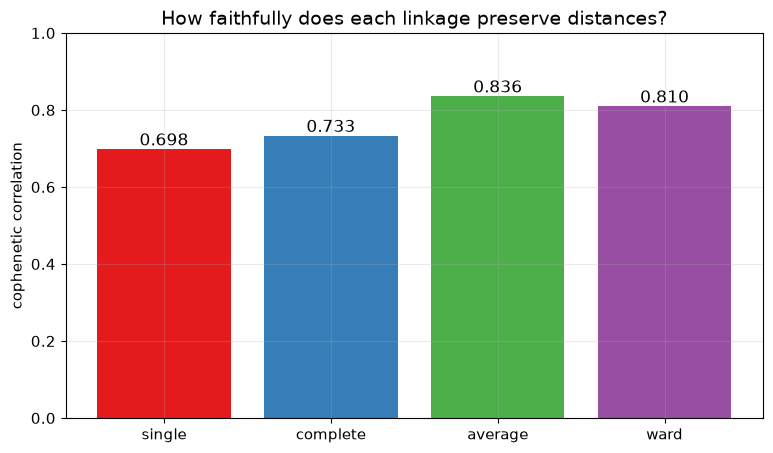

In [21]:

coph = {}
for method in METHODS:
    Z = linkage(X, method=method)
    c, _ = cophenet(Z, pdist(X))
    coph[method] = c

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(list(coph.keys()), list(coph.values()),
              color=["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"])
for bar, value in zip(bars, coph.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01,
            f"{value:.3f}", ha="center", fontsize=12)
ax.set_ylim(0, 1)
ax.set_ylabel("cophenetic correlation")
ax.set_title("How faithfully does each linkage preserve distances?", fontsize=14)
plt.show()



### What the numbers mean here

- **Average** has the highest cophenetic correlation - its tree is the most faithful summary of
  the pairwise distances.
- **Ward** is close behind.
- **Single** is lower on this dataset, because a few long "chain" merges distort the tree.

A high cophenetic correlation does **not** guarantee the clusters are meaningful - it only says
the tree represents the distances well. Always look at the scatter plot too.



## 18. Capstone: hierarchical vs K-Means vs DBSCAN

Same data, three different philosophies:

| Algorithm | What it assumes | What it returns |
|---|---|---|
| **K-Means** | `k` round clusters, every point assigned | exactly `k` labels |
| **Hierarchical (average)** | a tree of nested groups | `k` labels after cutting |
| **DBSCAN** | dense regions + noise | clusters **and** noise |

Notice that hierarchical clustering **cannot label a point as noise**. The 12 random points are
forced into whatever cluster is nearest. DBSCAN is the only one that can throw them away.


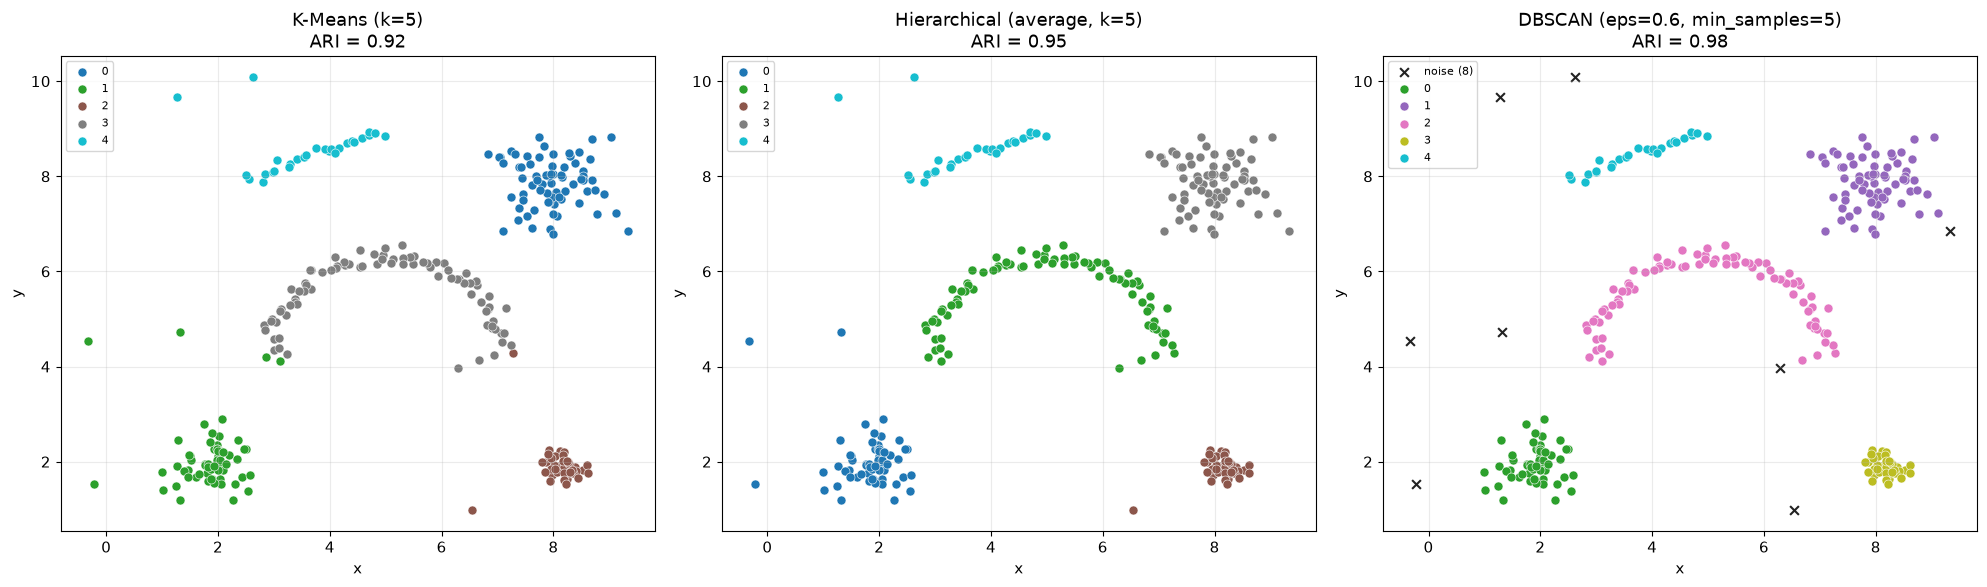

In [22]:

labels_km = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X)
labels_agg = AgglomerativeClustering(n_clusters=5, linkage="average").fit_predict(X)
labels_db = DBSCAN(eps=0.6, min_samples=5).fit_predict(X)

results = [
    ("K-Means (k=5)", labels_km),
    ("Hierarchical (average, k=5)", labels_agg),
    ("DBSCAN (eps=0.6, min_samples=5)", labels_db),
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (title, labels) in zip(axes, results):
    unique = sorted(set(labels))
    palette = plt.cm.tab10(np.linspace(0, 1, max(len(unique), 1)))
    for k, lab in enumerate(unique):
        m = labels == lab
        if lab == -1:
            ax.scatter(X[m, 0], X[m, 1], s=40, c="#222222", marker="x",
                       label=f"noise ({m.sum()})")
        else:
            ax.scatter(X[m, 0], X[m, 1], s=42, c=[palette[k % 10]],
                       label=str(lab), edgecolors="white", linewidths=0.4)
    ari = adjusted_rand_score(df["true_group"], labels)
    ax.set_title(f"{title}\nARI = {ari:.2f}", fontsize=13)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()



## 19. When to use hierarchical clustering

### Good fit

- You want to **see the structure** of the data, not just one flat partition.
- You do **not know `k`** and want to explore several granularities.
- The dataset is **small-to-medium** (hundreds to a few thousand points).
- You need a **deterministic**, reproducible result.
- You want a **dendrogram** for a report or a presentation.

### Bad fit

- **Millions of points** - the `O(n^2)` distance matrix will not fit in memory.
- You need to handle **noise / outliers** explicitly -> use **DBSCAN** or **HDBSCAN**.
- Clusters are **very different in size and density** -> Ward and complete may struggle;
  consider HDBSCAN.
- You need **online** clustering that updates as new data arrives -> use a different algorithm.

### Practical checklist

1. **Scale your features** - hierarchical clustering is distance-based.
2. Pick a **linkage** based on the shape you expect (see the table in section 3).
3. Build the **dendrogram** and look for the largest vertical gap.
4. Cut there, then **plot the result** and check it makes sense.
5. Compare with **silhouette** and, if you have labels, **ARI**.
6. Try at least two linkages - they often tell different stories.



## 20. Summary cheat sheet

| Concept | Meaning |
|---|---|
| **Agglomerative** | Bottom-up: each point starts alone, closest clusters merge repeatedly |
| **Divisive** | Top-down: one cluster is split repeatedly |
| **Dendrogram** | The tree picture of all merges |
| **Merge height** | How different the two merged clusters were |
| **Single linkage** | Minimum pairwise distance (can chain) |
| **Complete linkage** | Maximum pairwise distance (compact clusters) |
| **Average linkage** | Mean pairwise distance (balanced) |
| **Ward linkage** | Merge with the smallest increase in within-cluster variance |
| **Cutting the tree** | Choosing a height -> a flat clustering |
| **Cophenetic correlation** | How faithfully the tree preserves pairwise distances |

### The algorithm in 5 lines

1. Compute all pairwise distances.
2. Start with `n` singleton clusters.
3. Find the closest pair of clusters (using the chosen linkage).
4. Merge them and record the height.
5. Repeat `n - 1` times, then cut the tree where it makes sense.

### What to remember

- Hierarchical clustering gives you a **whole hierarchy**, not just one answer.
- **Linkage = your assumption about cluster shape.** Single follows chains, complete/Ward prefer
  compact blobs, average is the balanced default.
- It is **deterministic** and **interpretable**, but it does **not** detect noise.
- It costs `O(n^2)` memory, so it is not for huge datasets.
- **Scale your features**, plot the dendrogram, and try more than one linkage.

### Files in this folder

| File | Purpose |
|---|---|
| `hierarchical_points.csv` | The fake 2D dataset (282 points) |
| `Hierarchical clustering.ipynb` | This notebook |

> Try the playground once more: pick `single` linkage, then `complete`, then `ward`.
> The same data tells three different stories - and that is the most important lesson.
